# 01 · Entendimento do negócio e preparação dos dados

**Tech Challenge – Fase 1 · Case NPS (Net Promoter Score, ou índice de recomendação do cliente) Preditivo**

Este notebook cobre a parte de dados dos itens 1 e 2 do enunciado, e segue a sequência de avaliação apresentada na Aula 2:

1. Reconhecer a estrutura da base, a unidade de análise e os tipos de variável.
2. Avaliar a qualidade dos dados quanto a completude, consistência, validade, precisão e atualidade.
3. Tratar e documentar as inconsistências e os outliers (valores extremos).
4. Definir a target (variável alvo) e os riscos de usá-la de forma inadequada.
5. Salvar a base tratada para os próximos notebooks.

> As respostas completas de negócio estão em `reports/relatorio_negocio.md`.

## Pergunta orientadora e hipóteses

A pergunta orientadora foi formulada de forma específica e testável, como recomenda a Aula 1:

> **Quais fatores operacionais de pedido, logística e atendimento explicam por que um cliente se torna detrator, e como identificar esse risco antes da aplicação da pesquisa de NPS?**

Ela percorre os quatro níveis de pergunta analítica: **descritiva** (qual é o NPS e como se distribui), **diagnóstica** (quais fatores explicam os detratores), **preditiva** (qual a chance de um cliente se tornar detrator) e **prescritiva** (quais ações priorizar).

A partir dela foram levantadas cinco hipóteses, que o notebook 02 vai confirmar ou refutar:

| # | Hipótese | Área |
|---|---|---|
| H1 | Atraso na entrega derruba o NPS | Logística |
| H2 | Muitos contatos com o SAC (Serviço de Atendimento ao Consumidor) e resolução lenta derrubam o NPS | Atendimento |
| H3 | Mais reclamações levam a mais detratores | Atendimento / Produto |
| H4 | Frete caro e pouco desconto reduzem a satisfação | Pricing (precificação) |
| H5 | O perfil do cliente (região, idade, tempo de relacionamento) muda o NPS | Marketing / CRM (Customer Relationship Management, ou gestão de relacionamento com o cliente) |

In [1]:
# Bibliotecas e módulos do projeto
import sys
sys.path.append("..")  # permite importar a pasta src/ a partir de notebooks/

import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.data_prep import (load_raw_data, quality_report, validate_business_rules,
                           prepare_dataset, calculate_nps)
from src.viz import set_style, save

set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.2f}".format)

## 1. Reconhecimento da estrutura da base

In [2]:
df_raw = load_raw_data()
df_raw.head()

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.90,0,3,6.50
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.40,0,3,0.00
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.80,0,7,1.50
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.90,0,4,0.30
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.10,0,3,7.90


In [3]:
# Visão estrutural: número de linhas, tipos de dados e valores não nulos por coluna
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                2500 non-null   int64  
 1   customer_age               2500 non-null   int64  
 2   customer_region            2500 non-null   str    
 3   customer_tenure_months     2500 non-null   int64  
 4   order_id                   2500 non-null   int64  
 5   order_value                2500 non-null   float64
 6   items_quantity             2500 non-null   int64  
 7   discount_value             2500 non-null   float64
 8   payment_installments       2500 non-null   int64  
 9   delivery_time_days         2500 non-null   int64  
 10  delivery_delay_days        2500 non-null   int64  
 11  freight_value              2500 non-null   float64
 12  delivery_attempts          2500 non-null   int64  
 13  customer_service_contacts  2500 non-null   int64  
 14  res

A **unidade de análise** é o pedido de um cliente: são 2.500 linhas, com 2.500 clientes e 2.500 pedidos únicos, de modo que cada cliente aparece uma única vez na base.

Seguindo a classificação de tipos de variável da Aula 2, as colunas se organizam da seguinte forma:

| Bloco | Colunas | Tipo de variável |
|---|---|---|
| Identificação | `customer_id`, `order_id` | Identificador (não entra na análise) |
| Cliente | `customer_age`, `customer_tenure_months` | Numérica discreta |
| | `customer_region` | Categórica nominal |
| Pedido | `order_value`, `discount_value` | Numérica contínua |
| | `items_quantity`, `payment_installments` | Numérica discreta |
| Logística | `freight_value` | Numérica contínua |
| | `delivery_time_days`, `delivery_delay_days`, `delivery_attempts` | Numérica discreta |
| Atendimento | `customer_service_contacts`, `resolution_time_days`, `complaints_count` | Numérica discreta |
| Pós-jornada | `repeat_purchase_30d` | Booleana |
| | `csat_internal_score` | Numérica contínua |
| Alvo | `nps_score` | Numérica contínua (nota de 0 a 10) |

O dicionário de dados fornecido no enunciado descreve cada coluna, mas não traz a unidade de algumas delas nem a regra de cálculo de prazo e atraso, o que será retomado na avaliação de qualidade.

## 2. Avaliação da qualidade dos dados

A Aula 2 organiza a qualidade em cinco pilares, que são verificados a seguir.

### Completude e consistência

In [4]:
# Completude: quantidade de valores ausentes por coluna
df_raw.isnull().sum()

customer_id                  0
customer_age                 0
customer_region              0
customer_tenure_months       0
order_id                     0
order_value                  0
items_quantity               0
discount_value               0
payment_installments         0
delivery_time_days           0
delivery_delay_days          0
freight_value                0
delivery_attempts            0
customer_service_contacts    0
resolution_time_days         0
nps_score                    0
repeat_purchase_30d          0
complaints_count             0
csat_internal_score          0
dtype: int64

In [5]:
# Consistência: linhas duplicadas e identificadores repetidos
print("Linhas duplicadas:", df_raw.duplicated().sum())
print("Pedidos duplicados:", df_raw["order_id"].duplicated().sum())
print("Clientes duplicados:", df_raw["customer_id"].duplicated().sum())
print("Categorias de região:", sorted(df_raw["customer_region"].unique()))

Linhas duplicadas: 0
Pedidos duplicados: 0
Clientes duplicados: 0
Categorias de região: ['Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sul']


A base está completa, sem valores ausentes, e consistente, sem registros duplicados e com as cinco regiões escritas de forma padronizada.

### Validade e precisão

Para verificar a validade, observamos os limites de cada variável e checamos regras de negócio, ou seja, combinações de valores que não deveriam acontecer.

In [6]:
# Estatísticas descritivas das variáveis numéricas (sem os identificadores)
df_raw.drop(columns=config.ID_COLUMNS).describe().T

,count,mean,std,min,25%,50%,75%,max
customer_age,2500.00,43.40,14.89,18.00,31.00,43.00,56.00,69.00
customer_tenure_months,2500.00,61.32,34.48,1.00,31.00,62.00,91.00,119.00
order_value,2500.00,434.26,289.77,7.76,220.25,375.51,577.29,1983.81
items_quantity,2500.00,3.47,1.69,1.00,2.00,3.00,5.00,6.00
discount_value,2500.00,29.75,29.23,0.02,8.88,20.94,40.83,230.33
payment_installments,2500.00,6.00,3.16,1.00,3.00,6.00,9.00,11.00
delivery_time_days,2500.00,8.02,3.77,2.00,5.00,8.00,11.00,14.00
delivery_delay_days,2500.00,2.19,1.45,0.00,1.00,2.00,3.00,8.00
freight_value,2500.00,38.22,12.08,2.62,29.93,38.50,46.27,76.13
delivery_attempts,2500.00,2.01,0.82,1.00,1.00,2.00,3.00,3.00


In [7]:
# Resumo de qualidade por coluna: tipo, nulos, valores únicos, mínimo e máximo
quality_report(df_raw)

,tipo,nulos,valores_unicos,minimo,maximo
customer_id,int64,0,2500,1.00,2500.00
customer_age,int64,0,52,18.00,69.00
customer_region,str,0,5,NaN,NaN
customer_tenure_months,int64,0,119,1.00,119.00
order_id,int64,0,2500,50001.00,52500.00
order_value,float64,0,2457,7.76,1983.81
items_quantity,int64,0,6,1.00,6.00
discount_value,float64,0,2050,0.02,230.33
payment_installments,int64,0,11,1.00,11.00
delivery_time_days,int64,0,13,2.00,14.00


In [8]:
# Regras de negócio: quantas linhas violam cada regra
checks = validate_business_rules(df_raw)
pd.Series(checks, name="linhas que violam a regra").to_frame()

,linhas que violam a regra
linhas_duplicadas,0
pedidos_duplicados,0
nps_fora_de_0_a_10,0
csat_fora_de_0_a_10,0
idade_fora_de_18_a_100,0
valores_negativos,0
desconto_maior_que_pedido,35
atraso_maior_que_prazo_total,121
recompra_diferente_de_0_ou_1,0


Os limites são plausíveis, com idade entre 18 e 69 anos, notas de NPS e de CSAT (Customer Satisfaction Score, ou índice de satisfação do cliente) entre 0 e 10 e até 3 tentativas de entrega. Duas regras de validade, porém, foram violadas:

| Problema | Linhas | % da base | Hipótese provável |
|---|---|---|---|
| Desconto maior que o valor do pedido | 35 | 1,4% | Cupom aplicado também sobre o frete, ou itens devolvidos |
| Dias de atraso maiores que o prazo total | 121 | 4,8% | Definições diferentes para o cálculo do prazo e do atraso |

**Decisão:** manter as linhas e criar colunas de sinalização (`flag_*`), pelos seguintes motivos:

1. As linhas somam cerca de 6% da base, e a comparação abaixo mostra que removê-las não altera as conclusões.
2. Excluir dados sem confirmar a regra com a área responsável seria uma decisão arbitrária, e a Aula 2 recomenda avaliar o impacto antes de apagar qualquer registro.
3. Fica registrada a recomendação de confirmar, com o time de dados, a definição exata de `delivery_time_days` e `delivery_delay_days`.

Quanto à **precisão**, não há como verificar se cada valor é fiel à realidade sem a fonte original, e quanto à **atualidade**, a base não traz datas, o que impede saber de que período ela é.

In [9]:
df = prepare_dataset(df_raw)

inconsistent = (df["flag_desconto_maior_que_pedido"] == 1) | (df["flag_atraso_maior_que_prazo"] == 1)
print(f"Linhas sinalizadas: {inconsistent.sum()} ({inconsistent.mean():.1%})")
print(f"NPS com todas as linhas:       {calculate_nps(df['nps_score']):.1f}")
print(f"NPS sem as linhas sinalizadas: {calculate_nps(df.loc[~inconsistent, 'nps_score']):.1f}")

Linhas sinalizadas: 154 (6.2%)
NPS com todas as linhas:       -80.0
NPS sem as linhas sinalizadas: -79.1


O NPS praticamente não muda, passando de -80,0 para -79,1, e por isso todas as linhas foram mantidas.

### Outliers

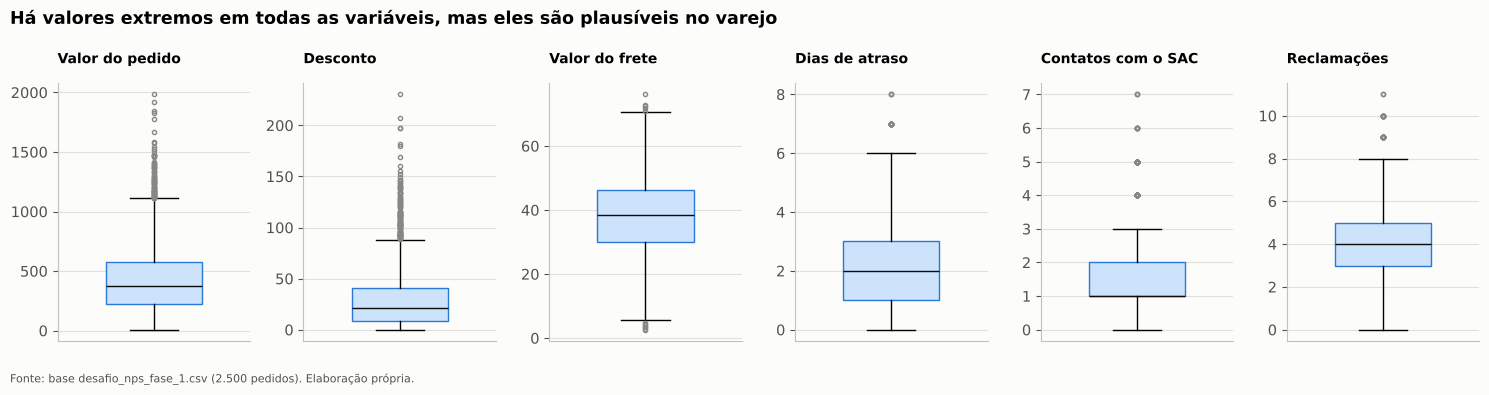

In [10]:
# Boxplots das variáveis contínuas e de contagem para identificar valores extremos
continuous = ["order_value", "discount_value", "freight_value", "delivery_delay_days",
              "customer_service_contacts", "complaints_count"]
fig, axes = plt.subplots(1, len(continuous), figsize=(15, 3.6))
for ax, col in zip(axes, continuous):
    ax.boxplot(df[col], widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", color=config.COLOR_MAIN),
               medianprops=dict(color=config.COLOR_TEXT), flierprops=dict(markeredgecolor="#898781", markersize=3))
    ax.set_title(config.FRIENDLY_NAMES[col], fontsize=10)
    ax.set_xticks([])
fig.suptitle("Há valores extremos em todas as variáveis, mas eles são plausíveis no varejo", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
save(fig, "00_outliers")

In [11]:
# Quantidade de valores acima do limite do boxplot (Q3 + 1,5 x IQR, ou intervalo interquartil)
def count_iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    return int((series > q3 + 1.5 * (q3 - q1)).sum())

pd.Series({c: count_iqr_outliers(df[c]) for c in continuous}, name="outliers (acima de Q3 + 1,5·IQR)").to_frame()

,"outliers (acima de Q3 + 1,5·IQR)"
order_value,84
discount_value,125
freight_value,5
delivery_delay_days,17
customer_service_contacts,176
complaints_count,29


**Decisão: manter os outliers.** Pedidos de quase R$ 2.000, 7 contatos com o SAC ou 8 dias de atraso são situações que podem ocorrer na operação, e são justamente os casos que ajudam a explicar a insatisfação. Como lembra a Aula 1, um valor atípico pode ser um erro de registro, mas também pode representar um caso que merece estudo, e aqui não há indício de erro.

### O recorte da realidade representado pela base

A Aula 2 lembra que nenhum dataset mostra a realidade completa, e esta base tem dois recortes importantes: ela contém apenas clientes que responderam à pesquisa de NPS, e não traz datas, o que impede analisar sazonalidade ou evolução ao longo do tempo.

## 3. Definição da target

### Qual variável representa a satisfação?

A variável é **`nps_score`**, a nota de 0 a 10 dada à pergunta "Quanto você recomendaria a empresa a um amigo?". A partir dela, foram criadas duas variáveis:

- `nps_category`, que classifica o cliente em Detrator (nota menor que 7), Neutro (de 7 a menos de 9) ou Promotor (9 ou mais);
- `is_detractor`, que vale 1 quando a nota é menor que 7 e é o alvo do modelo de classificação.

A nota foi escolhida porque é o indicador que a área de Experiência do Cliente já acompanha, e porque mede a disposição de recomendar a empresa, que está ligada à recompra. Ela é coletada **depois do encerramento da jornada de compra**, ou seja, após a entrega e o atendimento.

> A base traz notas com casas decimais, como 6,9, enquanto uma pesquisa NPS tradicional usa números inteiros. Foram adotados limites contínuos, em que 6,9 é detrator e 7,0 é neutro, regra que precisa ser confirmada com a área responsável.

In [12]:
# Distribuição das categorias de NPS
category_share = (df["nps_category"].value_counts(normalize=True)
                  .reindex(["Detrator", "Neutro", "Promotor"]) * 100)
nps_total = calculate_nps(df["nps_score"])
print(category_share.round(1).to_string())
print(f"\nNPS da empresa: {nps_total:.0f}")

nps_category
Detrator   84.40
Neutro     11.20
Promotor    4.40

NPS da empresa: -80


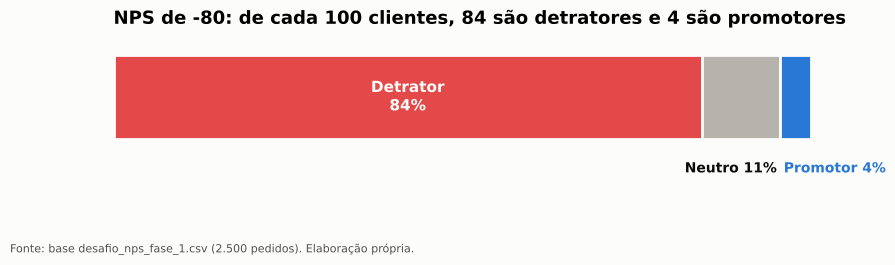

In [13]:
# Composição da base por categoria de NPS (barra empilhada, recomendada para composição)
fig, ax = plt.subplots(figsize=(9, 2.2))
left = 0
for category, share in category_share.items():
    ax.barh(0, share, left=left, color=config.CATEGORY_COLORS[category], edgecolor="#fcfcfb", linewidth=2, height=0.55)
    if share > 20:  # rótulo dentro da barra
        ax.text(left + share / 2, 0, f"{category}\n{share:.0f}%", ha="center", va="center",
                color="#fcfcfb", fontweight="bold", fontsize=11)
    elif category == "Neutro":   # segmentos pequenos: rótulo abaixo da barra
        ax.text(left + share - 0.5, -0.42, f"Neutro {share:.0f}%", ha="right", va="top",
                color=config.COLOR_TEXT, fontweight="bold", fontsize=10)
    else:
        ax.text(left + 0.5, -0.42, f"Promotor {share:.0f}%", ha="left", va="top",
                color=config.COLOR_PROMOTER, fontweight="bold", fontsize=10)
    left += share
ax.set_xlim(0, 100); ax.set_ylim(-0.75, 0.35); ax.set_yticks([]); ax.grid(False)
ax.spines[["left", "bottom"]].set_visible(False); ax.set_xticks([])
ax.set_title(f"NPS de {nps_total:.0f}: de cada 100 clientes, 84 são detratores e 4 são promotores")
save(fig, "01_distribuicao_nps")

O NPS da empresa é **-80**, resultado de 84% de detratores contra apenas 4% de promotores, o que significa que há cerca de 19 detratores para cada promotor.

### Existe risco de usar essa variável de forma inadequada?

Sim, e os principais riscos são:

1. **Vazamento de informação (*data leakage*):** as variáveis `csat_internal_score` e `repeat_purchase_30d` são medidas junto com o NPS ou depois dele, e usá-las para prever o NPS inflaria o desempenho do modelo. As tabelas abaixo mostram esse problema.
2. **Viés de resposta:** só responde à pesquisa quem quer, e clientes muito insatisfeitos tendem a responder mais.
3. **Uso individual da nota:** o NPS é um indicador de grupo, e usá-lo para avaliar ou punir uma pessoa, como um entregador, pode distorcer o comportamento.
4. **Correlação tratada como causa:** a análise mostra associações, e as ações precisam ser testadas, por exemplo com um teste A/B (comparação entre um grupo que recebe a mudança e outro que não recebe), antes de virar regra.

In [14]:
# Recompra em 30 dias por categoria de NPS (% de cada categoria)
pd.crosstab(df["nps_category"], df["repeat_purchase_30d"], normalize="index").mul(100).round(1)

repeat_purchase_30d,0,1
nps_category,,
Detrator,100.00,0.00
Neutro,61.60,38.40
Promotor,0.00,100.00


In [15]:
# Correlação de Spearman entre CSAT interno e NPS: as duas medidas são coletadas no mesmo momento
df[["nps_score", "csat_internal_score"]].corr(method="spearman").round(2)

,nps_score,csat_internal_score
nps_score,1.00,0.56
csat_internal_score,0.56,1.00


Todos os promotores recompraram em até 30 dias e nenhum detrator voltou a comprar, o que confirma o valor de negócio do NPS. Ainda assim, a recompra acontece **depois** da pesquisa e não pode ser usada para prevê-la. O CSAT, por sua vez, tem correlação de 0,56 com o NPS, mas também é coletado no fim da jornada.

Por isso, essas duas variáveis **são usadas na análise**, para mostrar o impacto do NPS, e **ficam fora do modelo**, para evitar o vazamento de informação.

## 4. Salvar a base tratada

Seguindo a orientação da Aula 2 de documentar cada alteração, a base tratada mantém todas as colunas originais e recebe apenas colunas novas, listadas abaixo.

In [16]:
config.PROCESSED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(config.PROCESSED_DATA_PATH, index=False)
print(f"Base tratada salva: {config.PROCESSED_DATA_PATH.name} | {df.shape[0]} linhas x {df.shape[1]} colunas")
print("Colunas criadas:", [c for c in df.columns if c not in df_raw.columns])

Base tratada salva: nps_tratado.csv | 2500 linhas x 30 colunas
Colunas criadas: ['flag_desconto_maior_que_pedido', 'flag_atraso_maior_que_prazo', 'nps_category', 'is_detractor', 'faixa_atraso', 'faixa_reclamacoes', 'faixa_contatos_sac', 'faixa_resolucao', 'faixa_idade', 'faixa_tempo_casa', 'faixa_valor_pedido']


## Resumo do notebook

- A base está completa e consistente, e 6% das linhas foram sinalizadas por inconsistência de validade, sem impacto nas conclusões.
- Os outliers foram mantidos, porque representam situações reais da operação.
- A target é `nps_score` na regressão e `is_detractor` na classificação.
- O NPS da empresa é **-80**, com 84% de detratores, 11% de neutros e 4% de promotores.
- As variáveis `csat_internal_score` e `repeat_purchase_30d` ficam fora do modelo por vazamento de informação.

Próximo notebook: `02_analise_exploratoria.ipynb`

## Glossário

| Termo | Significado |
|---|---|
| A/B (teste A/B) | Comparação entre um grupo que recebe uma mudança e outro que não recebe. |
| Boxplot | Gráfico que mostra mediana, quartis e valores extremos de uma variável. |
| Classificação | Tipo de modelo que prevê uma categoria, como detrator ou não detrator. |
| CRM (Customer Relationship Management) | Gestão do relacionamento com o cliente. |
| CSAT (Customer Satisfaction Score) | Nota de satisfação do cliente com uma interação específica. |
| Detrator | Cliente que deu nota de 0 a 6 e tende a não recomendar a empresa. |
| Flag | Coluna de sinalização (0 ou 1) que marca um caso especial sem apagá-lo. |
| IQR (Interquartile Range) | Intervalo interquartil, a distância entre o primeiro e o terceiro quartil, usado na regra de outliers. |
| Neutro | Cliente que deu nota 7 ou 8. |
| NPS (Net Promoter Score) | Percentual de promotores menos o percentual de detratores; varia de -100 a +100. |
| Outlier | Valor muito distante do padrão da variável, que nem sempre é um erro. |
| Pricing | Definição de preços, descontos e frete. |
| Promotor | Cliente que deu nota 9 ou 10 e tende a recomendar a empresa. |
| Regressão | Tipo de modelo que prevê um número, como a nota de 0 a 10. |
| SAC (Serviço de Atendimento ao Consumidor) | Canal de atendimento ao cliente. |
| Spearman (correlação de) | Medida, de -1 a +1, que indica se duas variáveis aumentam ou diminuem juntas. |
| Target (variável alvo) | Variável que se procura explicar ou prever. |
| Unidade de análise | O que cada linha da base representa; aqui, o pedido de um cliente. |
| Vazamento de informação (*data leakage*) | Uso, no modelo, de um dado que só existe depois do resultado, o que infla o desempenho. |
| Viés de resposta | Distorção causada porque apenas parte dos clientes responde à pesquisa. |